### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?



In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline 
 #TE PERMITE HACER PLOTS EN MITAD DE UNA LINEA SIN QUE TE LO PUSE
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?



In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.shape

(2443651, 9)

In [4]:
top_5_category = df['category'].value_counts().head(5).reset_index()
top_5_category

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [5]:
top_5_category_proportion = df['category'].value_counts(normalize=True).round(2).head(5).reset_index()
top_5_category_proportion

,category,proportion
0,Sports & Outdoors,0.34
1,Beauty,0.01
2,"Handmade Clothing, Shoes & Accessories",0.01
3,Bath & Body,0.01
4,Birthday Gifts,0.01


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\Darkos\AppData\Local\Temp\ipykernel_16380\153864779.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='category', y='count', data=top_5_category, palette='viridis')


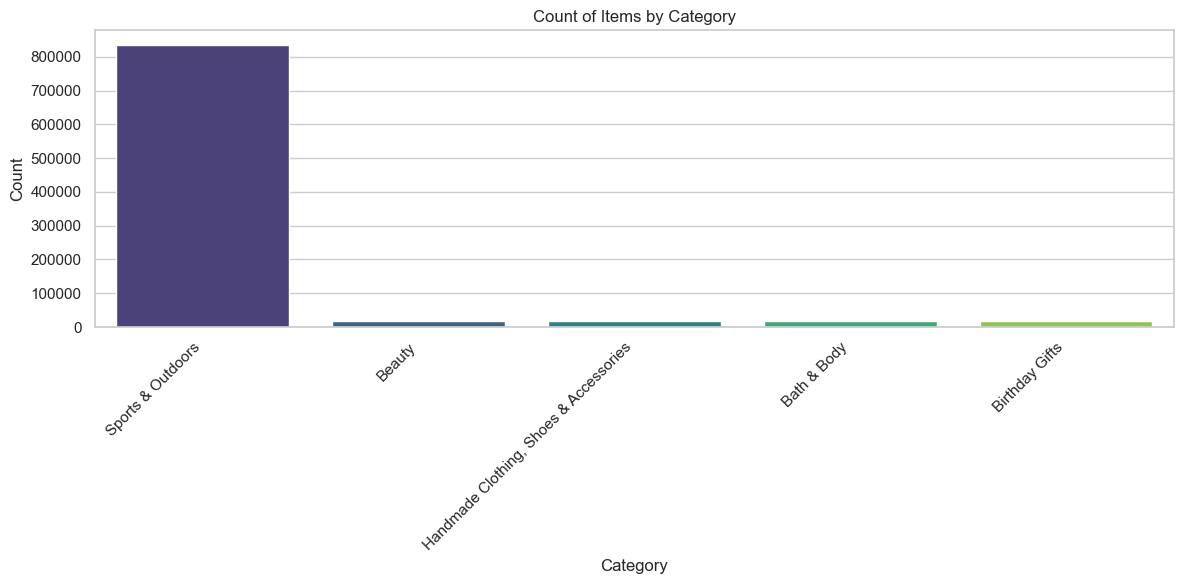

In [6]:

# Configurar el estilo de seaborn
sns.set_theme(style="whitegrid")

# Crear el barplot
plt.figure(figsize=(12, 6))
sns.barplot(x='category', y='count', data=top_5_category, palette='viridis')

# Personalizar etiquetas y título
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Count of Items by Category')
plt.xticks(rotation=45, ha='right')  # Rotar etiquetas para legibilidad
plt.tight_layout()  # Ajustar el layout

# Mostrar el gráfico
plt.show()

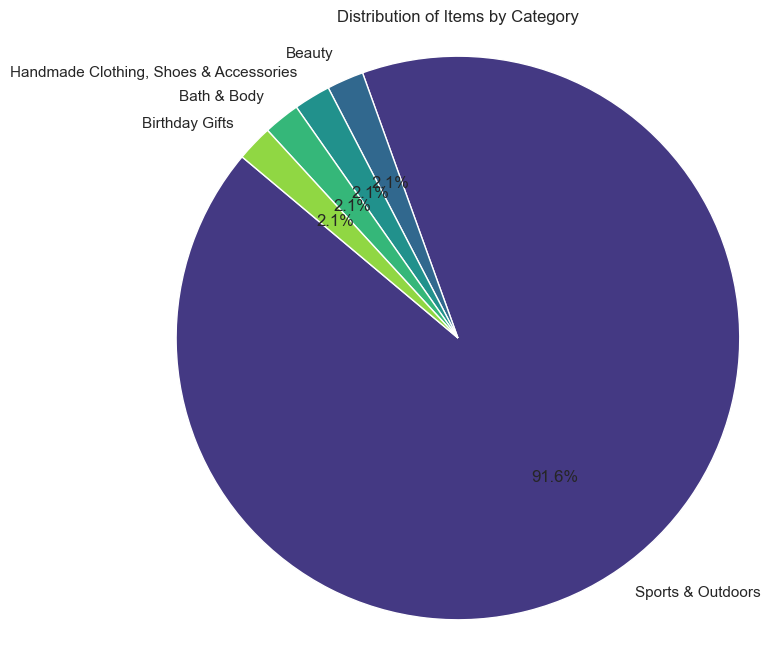

In [7]:
# Configurar el estilo de seaborn
sns.set_theme(style="whitegrid")

# Crear el gráfico de pastel
plt.figure(figsize=(8, 8))
plt.pie(top_5_category['count'], labels=top_5_category['category'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette("viridis", len(top_5_category)))

#autopct='%1.1f%%' ----> toma una cadena de formato que especifica cómo se debe mostrar el texto en las porciones del gráfico. 
#startangle=140  ---->  Este parámetro especifica el ángulo en grados a partir del cual se comienza a dibujar el primer segmento del gráfico de pastel

# Personalizar título
plt.title('Distribution of Items by Category')

# Mostrar el gráfico
plt.axis('equal')  # Igualar los ejes para que el gráfico sea un círculo
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
 

In [8]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
df['price'].mean().round(2)

89.24

In [10]:
df['price'].median()

19.09

In [11]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

- What's the average price point of products listed? How does this compare with the most common price point (mode)?

La media es de 89e mientras que la moda es de 10e. A pesar de que la media sea de 89, hay un gran porcentaje de e productos
que cuestan 9.99. Esto quiere decir, que hay pedidos con precios muy elevados que dispersan la media. 

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
   

In [12]:
round(df['price'].std(),2)

345.61

In [13]:
round(df['price'].var(),2)

119445.49

In [14]:
max_price = df['price'].max()
min_price = df['price'].min()
range = max_price - min_price

print(max_price)
print(min_price)
print(f'El rango es: {range}')

100000.0
0.0
El rango es: 100000.0


In [15]:
price_Q1 = df['price'].quantile(0.25)
price_Q3 = df['price'].quantile(0.75)
price_interquartile = price_Q3 - price_Q1


print(price_Q1)
print(price_Q3)
print(f'El intercuartil es: {price_interquartile}')

9.99
45.99
El intercuartil es: 36.0


El rango intercuartílico indica que hay una dispersión significativa en los precios. Un IQR de 36.0 sugiere que la diferencia entre el primer cuartil y el tercer cuartil es bastante amplia, lo que implica que los precios están distribuidos de manera más extensa en el conjunto de datos. Este rango puede ser útil para identificar valores atípicos en tus datos, ya que los valores que se encuentran fuera de este rango.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

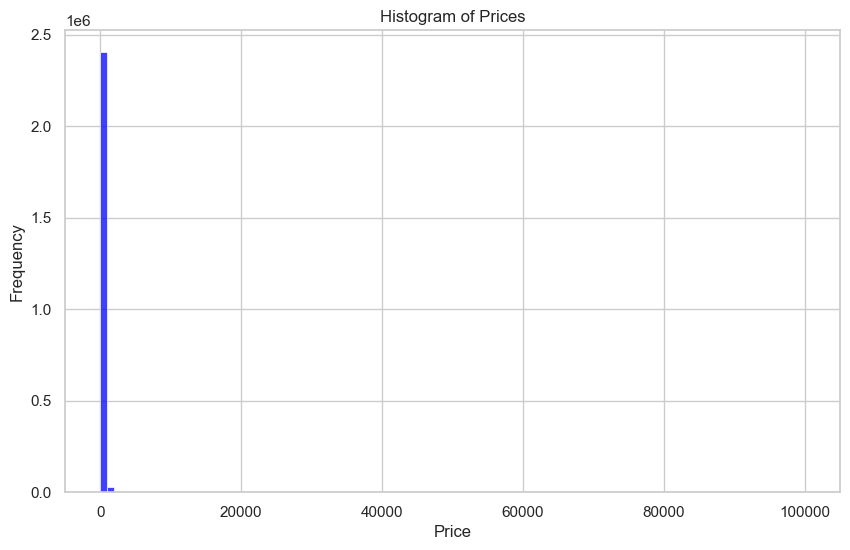

In [16]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=100, color='blue') 
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of Prices')
plt.grid(True)


plt.show()

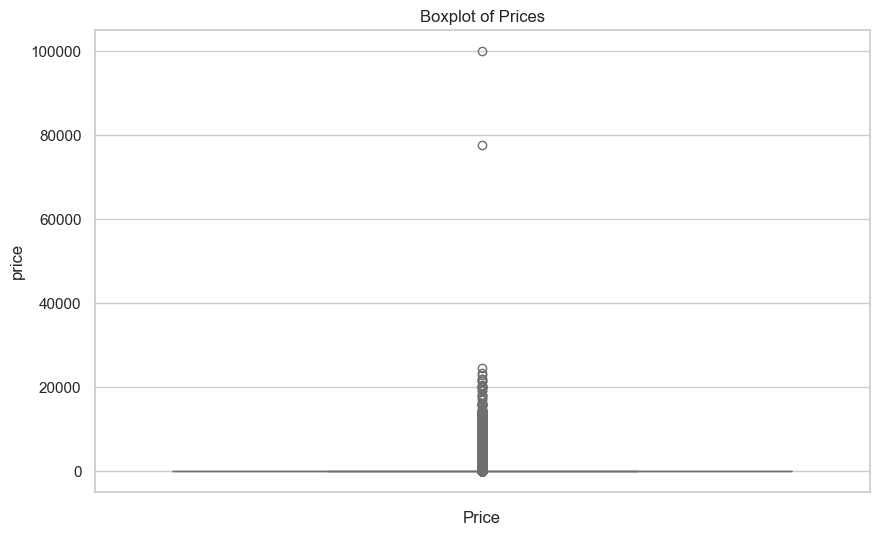

In [17]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(y=df['price'], color='skyblue')  

plt.xlabel('Price')
plt.title('Boxplot of Prices')

plt.show()


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [18]:
df['stars'].mean()

2.152836472966065

In [19]:
df['stars'].median()

0.0

In [20]:
df['stars'].mode()

0    0.0
Name: stars, dtype: float64

Los clientes por lo general votan con 0 esterellas

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [21]:
round(df['stars'].std(),2)

2.19

In [22]:
df['stars'].var()

4.81743402976196

In [23]:
rating_Q1 = df['stars'].quantile(0.25)
rating_Q2 = df['stars'].quantile(0.50)
rating_Q3 = df['stars'].quantile(0.75)
rating_IQR = rating_Q3 - rating_Q1

print(rating_Q1)
print(rating_Q2)
print(rating_Q3)
print(rating_IQR)

0.0
0.0
4.4
4.4


Existe una clara diferencia en los ratings: el 50% de ellos son del 0%, lo cual, en el caso de Amazon, indica que el usuario no ha dejado ninguna valoración.
 Esto evidencia una gran disparidad entre los clientes que proporcionan feedback y aquellos que no lo hacen.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [24]:
df['stars'].skew().round(2)

0.08

- Skewness > 0: The distribution is positively skewed (or right-skewed), meaning there is a longer tail on the right side of the distribution. The mass of the distribution is concentrated on the left of the figure

Ratings are not normally distributed

In [25]:
df['stars'].kurtosis().round(2)

-1.93

- Excess Kurtosis < 0 (or Kurtosis < 3 for non-excess): The distribution is platykurtic. It has thinner tails and a flatter peak than the normal distribution, indicating fewer extreme values than expected in a normal distribution.

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

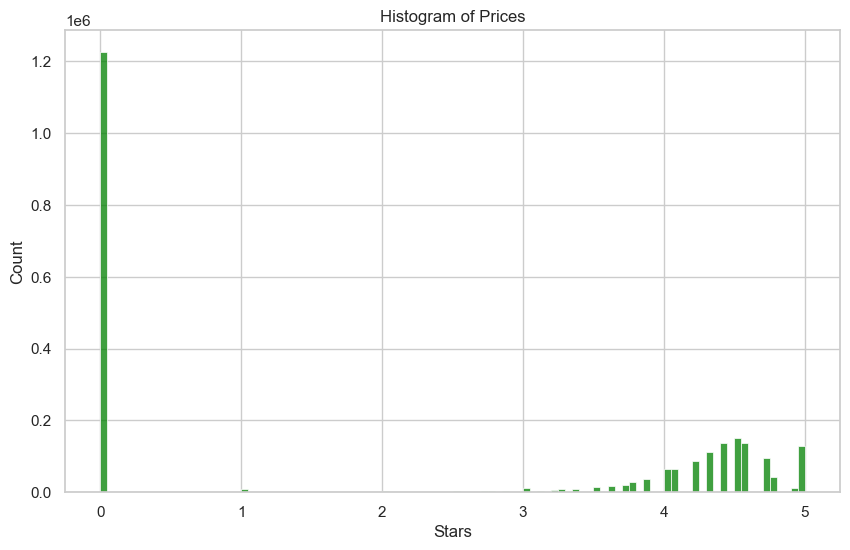

In [26]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=100, color='green') 
plt.xlabel('Stars')
plt.ylabel('Count')
plt.title('Histogram of Prices')
plt.grid(True)


plt.show()

In [27]:
ratings_depured = df[df['stars'] > 2] 

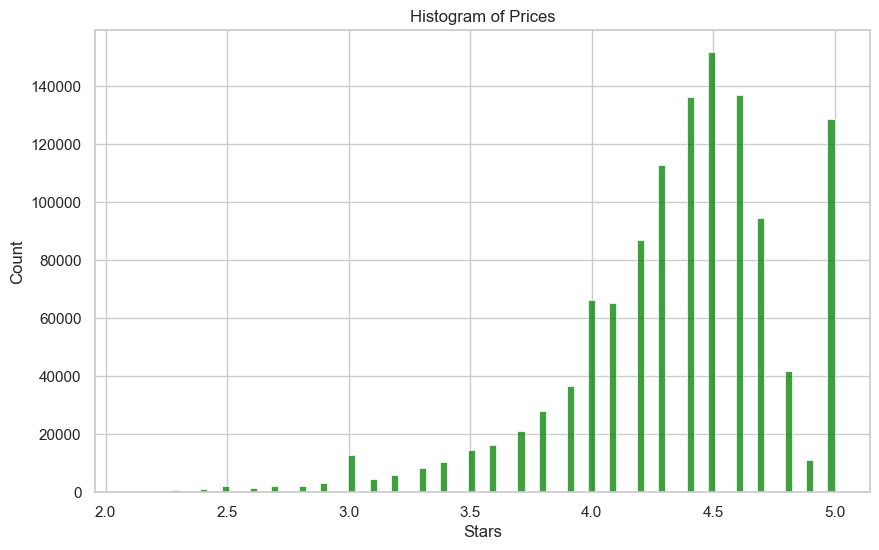

In [28]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(ratings_depured['stars'], bins=100, color='green') 
plt.xlabel('Stars')
plt.ylabel('Count')
plt.title('Histogram of Prices')
plt.grid(True)


plt.show()

In [29]:
ratings_depured['stars'].skew().round(2)

-1.18

- Skewness < 0: The distribution is negatively skewed (or left-skewed), meaning there is a longer tail on the left side of the distribution. The mass of the distribution is concentrated on the right of the figure.

Sin embargo, eliminando los datos de rating = 0, vemos que la distribucion tiene un aspecto totalmente opuesto.  